<a href="https://colab.research.google.com/github/fidha-rahma/03-02-2026/blob/main/Penjualan_Nusantara.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df = pd.read_csv('Penjualan-nusantara.csv')
print(df['total'].mean()) # rata-rata
print(df['total'].median()) # median
print(df['total'].std()) # standar deviasi
print(df['total'].quantile(0.25)) # Q1
print(df['total'].quantile(0.75)) # Q3
print(df.describe()) # ringkasan statistik seluruh kolom numerik

238486.36363636365
125000.0
371424.88168615586
55000.0
260000.0
          order_id      jumlah   harga_satuan         total  rating_pelanggan
count   220.000000  220.000000     220.000000  2.200000e+02        220.000000
mean   1110.500000    3.622727   63459.090909  2.384864e+05          4.154545
std      63.652704    4.865162   45395.201797  3.714249e+05          0.784395
min    1001.000000    1.000000   15000.000000  1.500000e+04          2.000000
25%    1055.750000    1.000000   28000.000000  5.500000e+04          4.000000
50%    1110.500000    3.000000   48000.000000  1.250000e+05          4.000000
75%    1165.250000    4.000000   90000.000000  2.600000e+05          5.000000
max    1220.000000   40.000000  175000.000000  3.400000e+06          5.000000


1. Kategori dengan rata-rata transaksi tertinggi dapat diketahui menggunakan perhitungan groupby() berdasarkan kategori produk.

2. Data kosong dapat dicek melalui df.info(). Jika jumlah Non-Null Count kurang dari total baris, berarti ada data kosong.

3. Mean total sebesar 238.486,36 dan median 125.000. Mean lebih besar karena beberapa transaksi bernilai tinggi, sehingga sebaran data cenderung miring ke kanan.

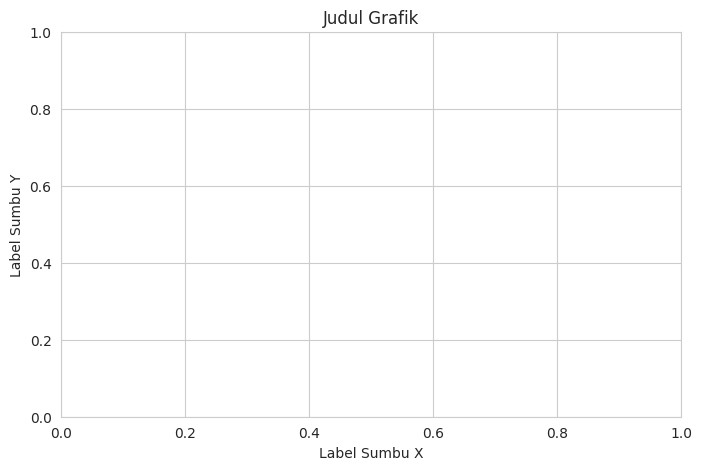

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
plt.figure(figsize=(8,5))
# ... perintah membuat grafik ...
plt.title('Judul Grafik')
plt.xlabel('Label Sumbu X')
plt.ylabel('Label Sumbu Y')
plt.show()

1. Kategori dengan penjualan tertinggi dan terendah belum diketahui karena grafik masih kosong.

2. Nusantara Mart perlu membuat grafik penjualan terlebih dahulu. Produk yang paling laris bisa ditambah stoknya, sedangkan produk yang kurang laku perlu dievaluasi dan dipromosikan agar penjualannya meningkat.

In [ ]:
import pandas as pd
df = pd.read_csv('Penjualan-nusantara.csv')
print(df.head()) # lihat 5 baris pertama
print(df.info()) # tipe data & jumlah data kosong
print(df.describe()) # ringkasan statistik
# rata-rata total pembelian per kategori produk
rata_kategori = df.groupby('kategori_produk')['total'].mean()
print(rata_kategori.sort_values(ascending=False))

   order_id     tanggal    kategori_produk        nama_produk   wilayah  \
0      1146  2026-01-03           Olahraga        Matras Yoga    Malang   
1      1166  2026-01-05            Fashion       Celana Jeans  Surabaya   
2      1190  2026-01-05          Kesehatan   Masker Medis Box  Semarang   
3      1219  2026-01-08  Makanan & Minuman  Kopi Kemasan 200g   Bandung   
4      1133  2026-01-10            Fashion         Tas Ransel  Surabaya   

   jumlah  harga_satuan   total metode_pembayaran  rating_pelanggan  
0       5         90000  450000          E-Wallet                 4  
1       5        175000  875000     Transfer Bank                 5  
2       4         30000  120000      Kartu Kredit                 3  
3       4         28000  112000          E-Wallet                 3  
4       4        130000  520000      Kartu Kredit                 4  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 10 columns):
 #   Column             

1. Bulan dengan penjualan tertinggi belum bisa diketahui karena data pada gambar belum menampilkan total penjualan per bulan. Kemungkinan penjualan meningkat karena promo, kebutuhan pelanggan, atau momen tertentu.

2. Tren penjualan belum bisa dipastikan apakah naik, turun, atau fluktuatif karena perlu melihat grafik penjualan per bulan terlebih dahulu.

/tmp/ipykernel_4123/1140824476.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


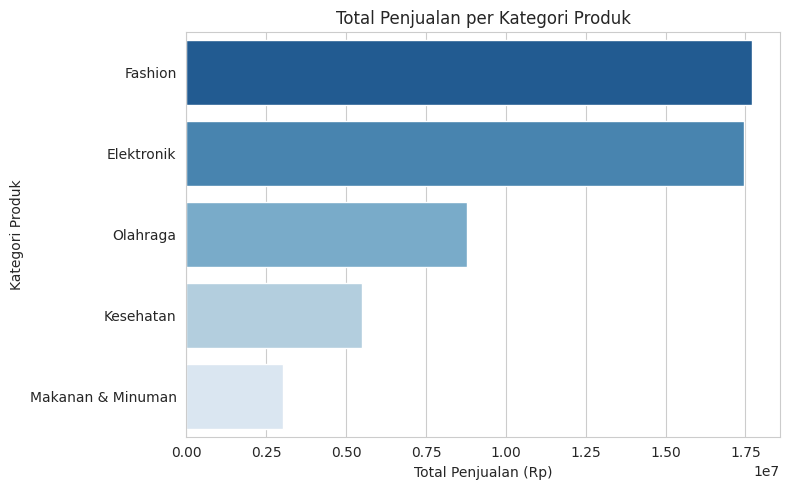

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
total_kategori = df.groupby('kategori_produk')['total'].sum().sort_values(ascending=False)
plt.figure(figsize=(8,5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')

plt.tight_layout()
plt.show()

1. Hubungan jumlah barang dan total transaksi cenderung positif, karena semakin banyak barang yang dibeli, biasanya semakin besar total transaksinya.

2. Kemungkinan outlier belum bisa dipastikan dari grafik ini karena grafik hanya menampilkan total penjualan berdasarkan kategori produk, bukan hubungan jumlah barang dengan total transaksi.

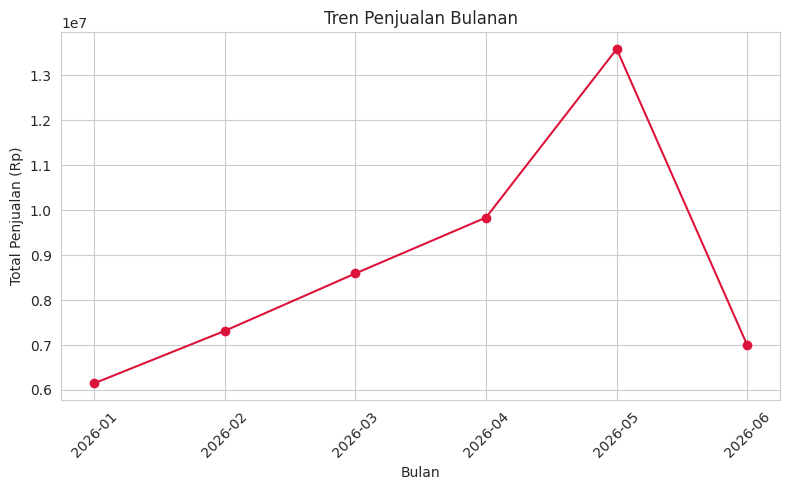

In [ ]:
df['tanggal'] = pd.to_datetime(df['tanggal'])
df['bulan'] = df['tanggal'].dt.to_period('M')
tren_bulanan = df.groupby('bulan')['total'].sum()
plt.figure(figsize=(8,5))
plt.plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o', color='crimson')
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

1. Penjualan tertinggi terjadi pada Mei 2026, kemungkinan karena adanya promo atau meningkatnya kebutuhan pelanggan.

2. Tren penjualan cenderung naik dari Januari hingga Mei, tetapi turun drastis pada Juni. Hal ini menunjukkan penjualan masih fluktuatif.

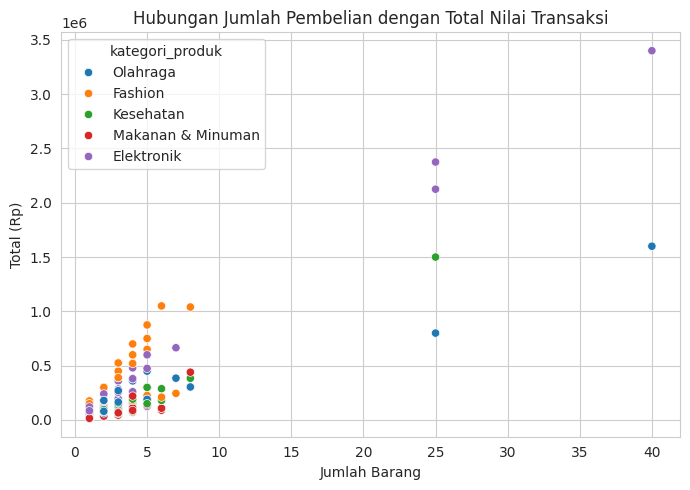

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='jumlah', y='total', hue='kategori_produk')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

1. Terlihat hubungan positif antara jumlah barang dan total nilai transaksi. Semakin banyak barang yang dibeli, biasanya semakin besar total transaksinya.

2. Terdapat titik yang jauh dari pola umum pada kategori Elektronik (ungu), Olahraga (biru), dan Kesehatan (hijau). Hal ini bisa disebabkan oleh pembelian dalam jumlah besar, misalnya oleh reseller.

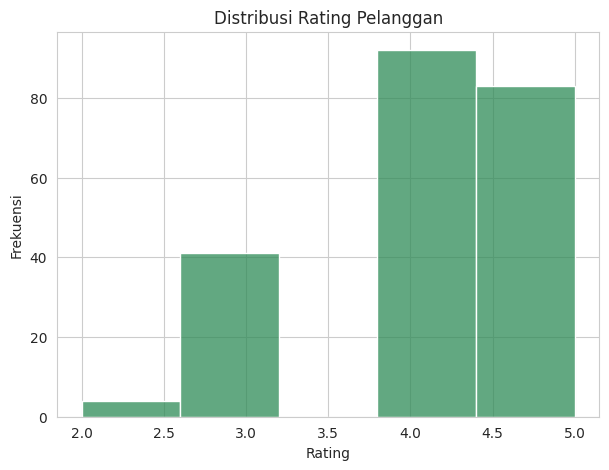

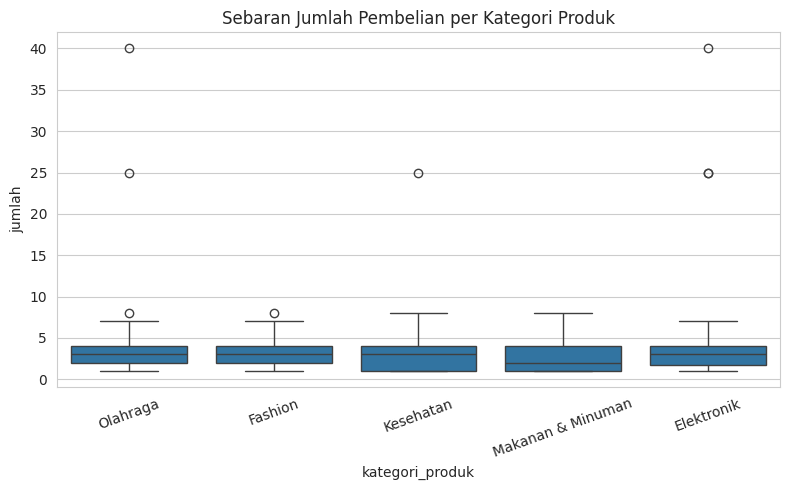

In [ ]:
# Histogram distribusi rating pelanggan
plt.figure(figsize=(7,5))
sns.histplot(df['rating_pelanggan'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()
# Boxplot jumlah pembelian per kategori (deteksi outlier)
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='kategori_produk', y='jumlah')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

1. Distribusi rating pelanggan cenderung tinggi karena sebagian besar pelanggan memberikan rating 4 dan 5.

2. Outlier terlihat pada kategori Olahraga, Fashion, Kesehatan, dan Elektronik. Hal ini kemungkinan disebabkan oleh pembelian dalam jumlah besar, misalnya oleh reseller.

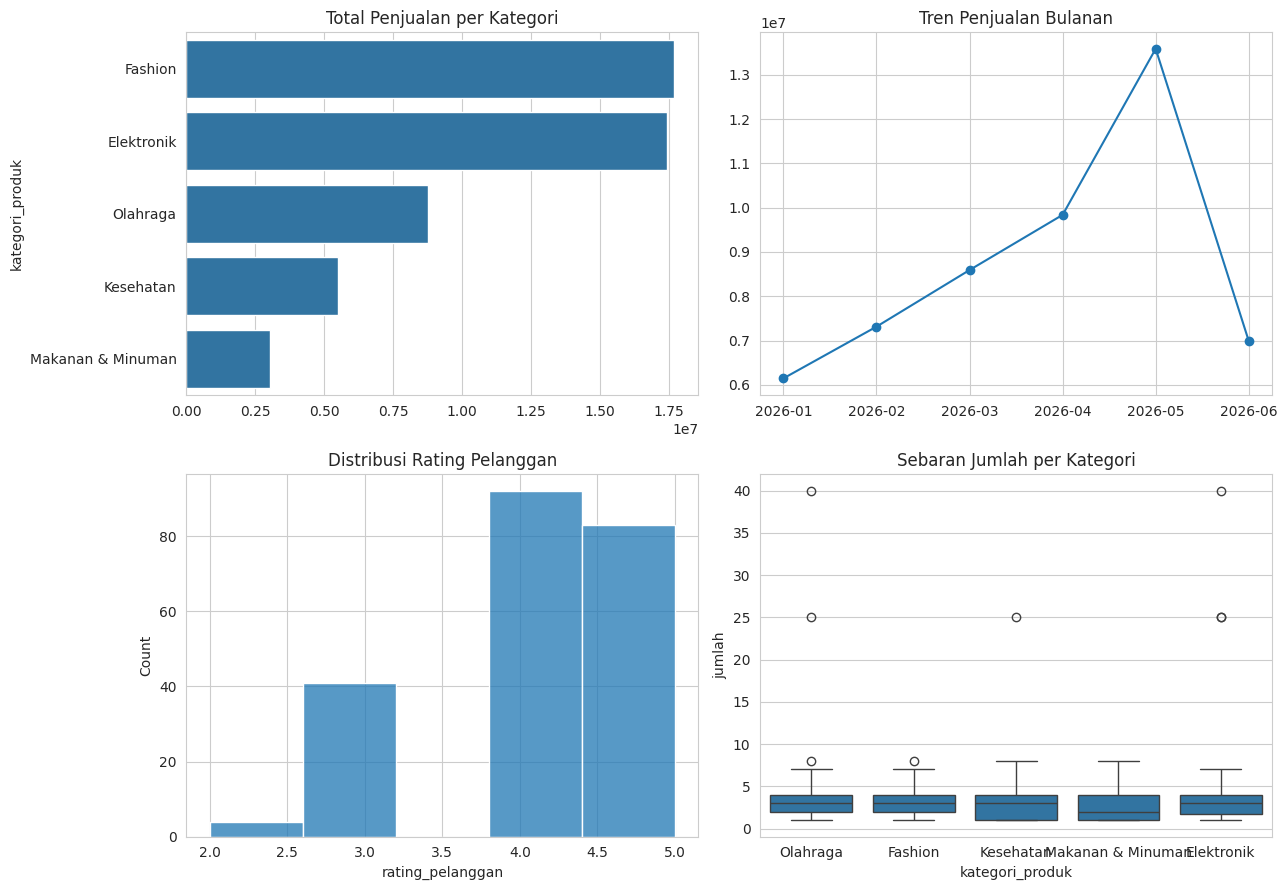

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13,9))
sns.barplot(x=total_kategori.values, y=total_kategori.index, ax=axes[0,0])
axes[0,0].set_title('Total Penjualan per Kategori')
axes[0,1].plot(tren_bulanan.index.astype(str), tren_bulanan.values, marker='o')
axes[0,1].set_title('Tren Penjualan Bulanan')
sns.histplot(df['rating_pelanggan'], bins=5, ax=axes[1,0])
axes[1,0].set_title('Distribusi Rating Pelanggan')
sns.boxplot(data=df, x='kategori_produk', y='jumlah', ax=axes[1,1])
axes[1,1].set_title('Sebaran Jumlah per Kategori')
plt.tight_layout()
plt.show()

1. Dashboard memudahkan manajer melihat perbandingan penjualan, tren bulanan, rating pelanggan, dan jumlah barang dalam satu tampilan sehingga analisis lebih cepat.

2. Nusantara Mart sebaiknya menambah stok produk Fashion dan Elektronik karena penjualannya paling tinggi. Penjualan Makanan & Minuman perlu ditingkatkan melalui promosi. Selain itu, penjualan bulan Juni perlu dievaluasi karena mengalami penurunan, meskipun penjualan sebelumnya meningkat.